# 02 Exploratory Data Analysis

**Goal:** answer business questions about Olist orders, deliveries and reviews.
Each question gets one chart and one sentence on what a shop should do.

**Data:** `orders_clean.parquet` from 01_cleaning (99,441 orders, 27 columns).

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROCESSED = r"..\data\processed"
orders = pd.read_parquet(PROCESSED + r"\orders_clean.parquet")

delivered = orders[orders['order_delivered_customer_date'].notna()]
print(orders.shape, delivered.shape)

(99441, 27) (96476, 27)


## Q1. How did orders grow over time?
Count orders per month to see growth and seasonality.

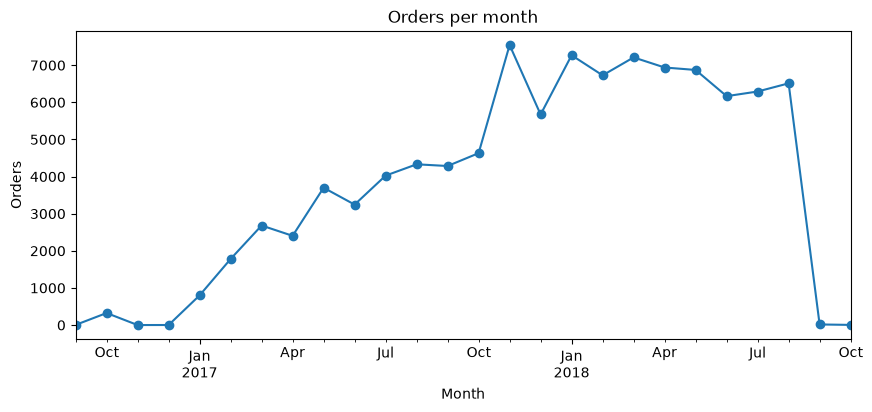

In [2]:
monthly = orders.set_index('order_purchase_timestamp').resample('ME')['order_id'].count()

monthly.plot(figsize=(10, 4), marker='o')
plt.title('Orders per month')
plt.xlabel('Month')
plt.ylabel('Orders')
plt.show()

In [3]:
monthly.idxmax(), monthly.max()

(Timestamp('2017-11-30 00:00:00'), np.int64(7544))

In [4]:
monthly.head(6)

order_purchase_timestamp
2016-09-30       4
2016-10-31     324
2016-11-30       0
2016-12-31       1
2017-01-31     800
2017-02-28    1780
Freq: ME, Name: order_id, dtype: int64

In [5]:
monthly.tail(4)

order_purchase_timestamp
2018-07-31    6292
2018-08-31    6512
2018-09-30      16
2018-10-31       4
Freq: ME, Name: order_id, dtype: int64

Incomplete months are removed before drawing conclusions. Otherwise the chart would suggest that sales collapsed in September 2018, which is wrong. The chart redrawn with the reliable period only:

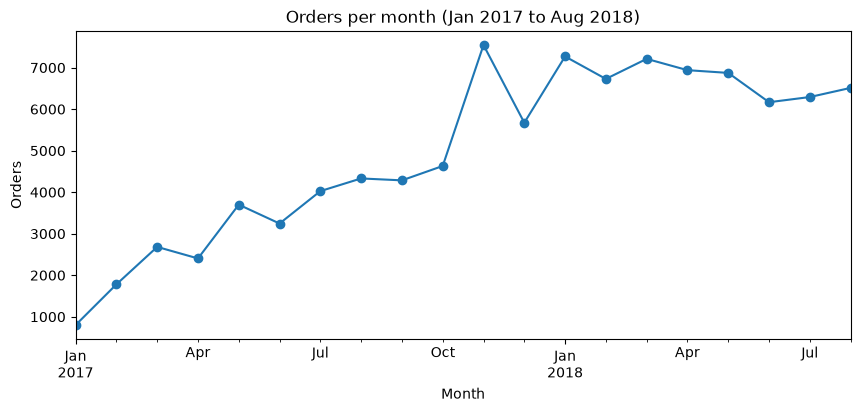

In [6]:
monthly_ok = monthly['2017-01':'2018-08']
monthly_ok.plot(figsize=(10, 4), marker='o')
plt.title('Orders per month (Jan 2017 to Aug 2018)')
plt.ylabel('Orders')
plt.xlabel('Month')
plt.show()

Orders grew steadily through 2017, from under 1,000 a month in January to a peak of about 7,500 in November 2017 (Black Friday). From January to August 2018 volume levelled off at about 6,000 to 7,000 orders a month. Months before 2017 and after August 2018 are incomplete in the dataset, so they are excluded. For a shop: plan stock and delivery capacity for November, when demand spikes, and expect late deliveries then.

## Q2. Which categories bring the most revenue?
Total item revenue per category (category = the first item in each order), delivered orders only.

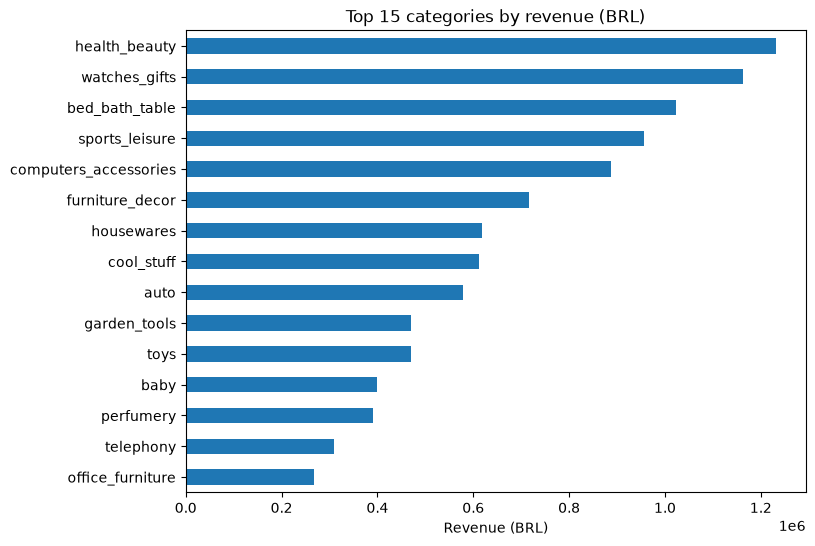

In [7]:
cat_revenue = (delivered
    .groupby('category')['total_price']
    .sum()
    .sort_values(ascending=False)
)

top15 = cat_revenue.head(15)
top15.sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Top 15 categories by revenue (BRL)')
plt.xlabel('Revenue (BRL)')
plt.ylabel('')
plt.show()

Horizontal bars (`kind='barh'`) are easier to read with long category names.

In [8]:
share_top5 = cat_revenue.head(5).sum() / cat_revenue.sum()
print(len(cat_revenue), 'categories; top 5 =', round(share_top5 * 100, 1), '% of revenue')

74 categories; top 5 = 39.8 % of revenue


**Finding:** Health & beauty earns the most (about 1.23 million BRL), followed by watches & gifts (about 1.16 million) and bed, bath & table (about 1.02 million).
The top 5 of 74 categories bring in **39.8%** of revenue, so revenue is concentrated in a few categories.
Bed, bath & table has the most products listed but ranks third in revenue: a big catalogue does not mean the most sales.

**For a shop:** focus marketing budget and delivery quality on the top 5 categories, where 40% of the money is.

*Limitation: each order is counted under the category of its first item; 75%+ of orders have one item, so the effect is small.*

## Q3. How are review scores distributed?
Share of each score from 1 to 5, delivered orders with a review.

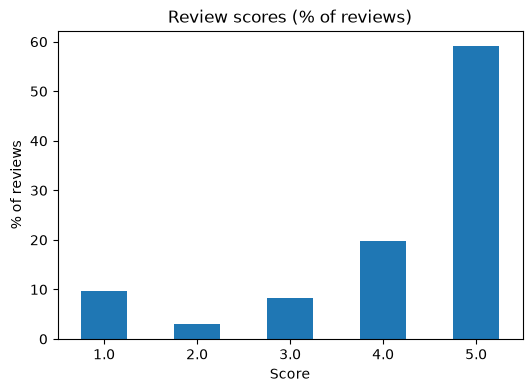

review_score
1.0     9.8
2.0     3.0
3.0     8.3
4.0    19.7
5.0    59.2
Name: proportion, dtype: float64


In [9]:
score_share = delivered['review_score'].value_counts(normalize=True).sort_index() * 100

score_share.plot(kind='bar', figsize=(6, 4))
plt.title('Review scores (% of reviews)')
plt.xlabel('Score')
plt.ylabel('% of reviews')
plt.xticks(rotation=0)
plt.show()

print(score_share.round(1))

**Finding:** Among delivered orders, 59.2% of reviews give 5 stars and 19.7% give 4, so about 79% are positive.
12.8% give 1 or 2 stars. Bad reviews are a minority, but 1-star (9.8%) is more common than 2 or 3 stars.
The distribution is J-shaped: customers mostly review when they are very satisfied or very dissatisfied.
Bad reviews are less common among delivered orders (12.8%) than across all orders (about 15%), which suggests delivery problems drive part of the dissatisfaction.

**For a shop:** a 1-star review usually signals a specific failure, not mild disappointment, so it is worth finding the cause. Q4 tests whether late delivery is that cause.

## Q4. Do late deliveries get worse reviews?
Compare review scores for late vs on-time delivered orders.

In [10]:
q4 = delivered.groupby('is_late').agg(
    orders=('order_id', 'count'),
    avg_score=('review_score', 'mean'),
    bad_share=('review_score', lambda s: (s <= 2).mean() * 100),
)
q4.round(2)

,orders,avg_score,bad_share
is_late,,,
False,89941,4.29,9.22
True,6535,2.27,60.95


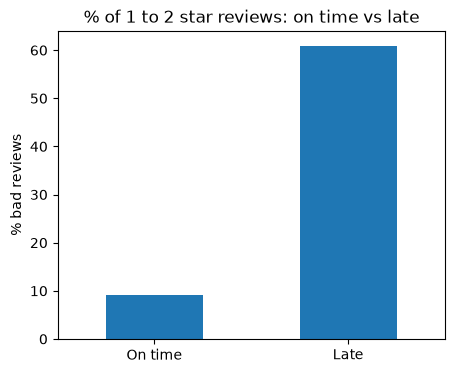

In [11]:
q4['bad_share'].plot(kind='bar', figsize=(5, 4))
plt.title('% of 1 to 2 star reviews: on time vs late')
plt.xticks([0, 1], ['On time', 'Late'], rotation=0)
plt.ylabel('% bad reviews')
plt.xlabel('')
plt.show()

What share of all bad reviews comes from late orders?

In [12]:
bad = delivered[delivered['review_score'] <= 2]
bad['is_late'].mean() * 100

np.float64(32.445421961551)

**Finding:** Late delivery is strongly linked to bad reviews.
61% of late orders got a 1 or 2 star review, against 9.2% of on-time orders: a late order is 6.6 times more likely to be reviewed badly.
The average score drops from 4.29 (on time) to 2.27 (late).
Late orders are only 6.8% of delivered orders but account for **32.4%** of all bad reviews.

**For a shop:** preventing late deliveries, or contacting customers before a delay, is the single biggest lever on review scores.
The remaining bad reviews come from on-time orders, so product or seller issues also matter (see Q8).

*Note: this shows a strong link, not proof of cause. Stage 3 tests it with a model.*

## Q5. Does a longer delay make reviews worse?
Group delivered orders by how early or late they arrived, then compare review scores per group.

In [13]:
bins = [-float('inf'), -8, -1, 0, 3, 7, float('inf')]
labels = ['8+ days early', '1-7 days early', 'On the day', '1-3 days late', '4-7 days late', '8+ days late']

delivered = delivered.copy()
delivered['delay_bucket'] = pd.cut(delivered['delay_days'], bins=bins, labels=labels)
delivered['delay_bucket'].value_counts().sort_index()

delay_bucket
8+ days early     71308
1-7 days early    17341
On the day         1292
1-3 days late      1870
4-7 days late      1802
8+ days late       2863
Name: count, dtype: int64

In [14]:
q5 = delivered.groupby('delay_bucket', observed=True).agg(
    orders=('order_id', 'count'),
    avg_score=('review_score', 'mean'),
    bad_share=('review_score', lambda s: (s <= 2).mean() * 100),
)
q5.round(2)

,orders,avg_score,bad_share
delay_bucket,,,
8+ days early,71308,4.32,8.93
1-7 days early,17341,4.20,10.18
On the day,1292,4.03,12.31
1-3 days late,1870,3.29,31.82
4-7 days late,1802,2.10,65.65
8+ days late,2863,1.70,77.02


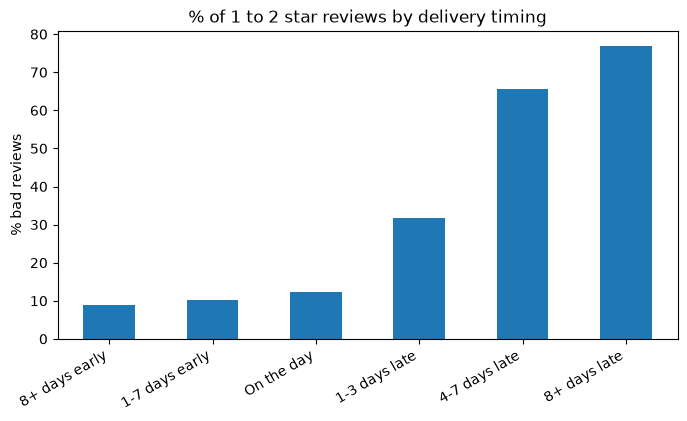

In [15]:
q5['bad_share'].plot(kind='bar', figsize=(8, 4))
plt.title('% of 1 to 2 star reviews by delivery timing')
plt.ylabel('% bad reviews')
plt.xlabel('')
plt.xticks(rotation=30, ha='right')
plt.show()

**Finding:** Bad reviews stay low while orders arrive early or on the day (8.9% to 12.3%), then rise sharply with every day of delay:
31.8% at 1 to 3 days late, 65.7% at 4 to 7 days, and 77.0% at 8+ days. The average score falls from 4.32 to 1.70.
Even a short delay matters: 1 to 3 days late makes a bad review 2.6 times more likely than delivery on the day.
Arriving very early barely helps (8.9% vs 10.2% for 1 to 7 days early).

**For a shop:** the goal is "never late", not "as fast as possible". Promise a realistic date, and contact the customer as soon as an order is at risk of missing it, especially before day 4, when bad reviews pass 50%.

## Q6. Where are deliveries slowest?
Median delivery days and late share per customer state (Brazil has 27 states, shown as 2-letter codes, e.g. SP = São Paulo).

In [16]:
q6 = delivered.groupby('customer_state').agg(
    orders=('order_id', 'count'),
    median_days=('delivery_days', 'median'),
    late_share=('is_late', lambda s: s.mean() * 100),
    avg_score=('review_score', 'mean'),
).sort_values('median_days', ascending=False)

q6.round(1)

,orders,median_days,late_share,avg_score
customer_state,,,,
AM,145,25.0,2.8,4.2
RR,41,25.0,12.2,3.9
AP,67,24.0,3.0,4.2
AL,397,22.0,21.4,3.8
PA,946,21.0,11.2,3.9
MA,717,19.0,17.4,3.8
AC,80,18.0,3.8,4.1
PB,517,18.0,10.4,4.1
SE,335,18.0,15.2,3.9


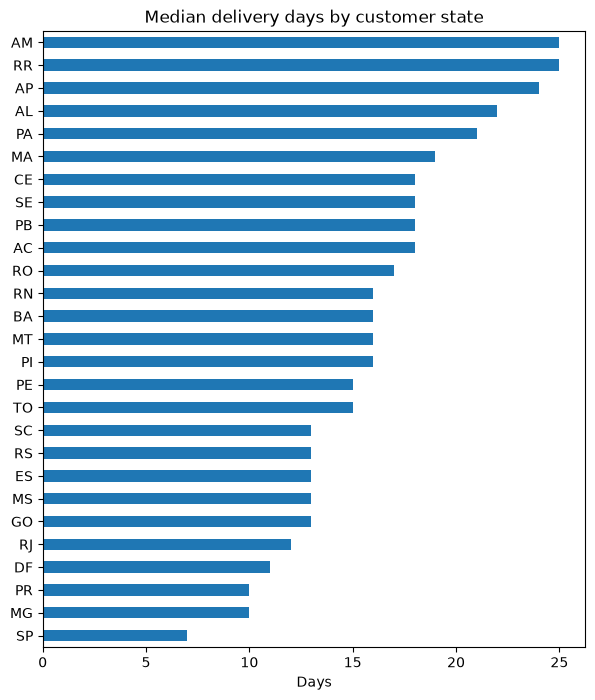

In [17]:
q6['median_days'].sort_values().plot(kind='barh', figsize=(7, 8))
plt.title('Median delivery days by customer state')
plt.xlabel('Days')
plt.ylabel('')
plt.show()

In [18]:
q6[['median_days', 'late_share', 'avg_score']].corr().round(2)

,median_days,late_share,avg_score
median_days,1.00,0.27,-0.40
late_share,0.27,1.00,-0.88
avg_score,-0.40,-0.88,1.00


**Finding:** Delivery time depends strongly on region. São Paulo (SP), the biggest market with 42% of delivered orders, has the fastest delivery (median 7 days); northern states such as Amazonas (AM) take about 25 days, 3.6 times longer.
But slow does not mean unhappy: across states, the share of late orders is strongly linked to review scores (correlation −0.88), while delivery time alone is only moderately linked (−0.40).
Amazonas is the slowest state yet has only 2.8% late orders and an average score of 4.2. Alagoas (AL) takes a similar 22 days but has 21.4% late orders and the lowest score (3.8).

**For a shop:** customers accept long delivery times when the promise is realistic. Set honest delivery estimates per region, especially in the north and north-east, rather than promising speed you cannot deliver.

*Note: states with under 100 orders (RR, AP, AC) are too small to compare reliably. Correlation across 27 states is a rough check, not proof.*

## Q7. Does expensive freight link to worse reviews?
Split delivered orders into 5 equal groups by freight share (freight ÷ order value) and compare review scores.

In [19]:
delivered['freight_group'] = pd.qcut(
    delivered['freight_share'], q=5,
    labels=['1 lowest', '2', '3', '4', '5 highest']
)
delivered['freight_group'].value_counts().sort_index()

freight_group
1 lowest     19296
2            19295
3            19301
4            19297
5 highest    19287
Name: count, dtype: int64

In [20]:
q7 = delivered.groupby('freight_group', observed=True).agg(
    orders=('order_id', 'count'),
    freight_share_range=('freight_share', lambda s: f"{s.min():.0%} to {s.max():.0%}"),
    bad_share=('review_score', lambda s: (s <= 2).mean() * 100),
    late_share=('is_late', lambda s: s.mean() * 100),
    median_days=('delivery_days', 'median'),
)
q7.round(1)

,orders,freight_share_range,bad_share,late_share,median_days
freight_group,,,,,
1 lowest,19296,0% to 10%,12.3,6.8,9.0
2,19295,10% to 15%,12.2,6.6,9.0
3,19301,15% to 21%,12.2,6.4,10.0
4,19297,21% to 30%,13.4,7.0,10.0
5 highest,19287,30% to 96%,13.4,7.0,11.0


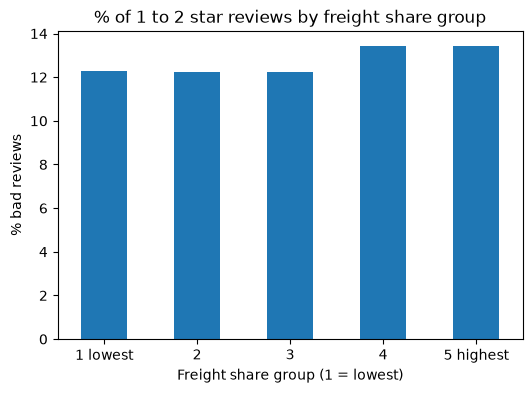

In [21]:
q7['bad_share'].plot(kind='bar', figsize=(6, 4))
plt.title('% of 1 to 2 star reviews by freight share group')
plt.ylabel('% bad reviews')
plt.xlabel('Freight share group (1 = lowest)')
plt.xticks(rotation=0)
plt.show()

**Finding:** Freight cost relative to price has only a small link to bad reviews.
Orders where shipping is 0 to 21% of the price get 12.2% to 12.3% bad reviews; orders where it is 21% to 96% get 13.4%, a rise of 1.1 percentage points.
Late share stays flat across the groups (6.4% to 7.0%), so the small rise is not explained by more late deliveries.
Compared with delivery delay (bad reviews rise from 12% to 77%), freight cost is a minor factor.

**For a shop:** reducing shipping costs is unlikely to improve reviews much. Delivering on time matters far more than delivering cheaply.

## Q8. Which categories get the most bad reviews?
Share of 1 to 2 star reviews per category, on-time orders only (to remove the delivery effect), categories with at least 200 reviewed orders.

In [22]:
delivered['is_bad'] = delivered['review_score'] <= 2
on_time = delivered[(delivered['is_late'] == False) & delivered['review_score'].notna()]
on_time.shape

(89448, 30)

In [23]:
q8 = on_time.groupby('category').agg(
    orders=('order_id', 'count'),
    bad_share=('is_bad', 'mean'),
    avg_score=('review_score', 'mean'),
)
q8 = q8[q8['orders'] >= 200].sort_values('bad_share', ascending=False)
q8.head(10).round(3)

,orders,bad_share,avg_score
category,,,
office_furniture,1137,0.184,3.764
home_confort,333,0.141,4.078
fixed_telephony,200,0.140,4.060
audio,301,0.140,4.130
unknown,1254,0.128,4.179
home_construction,435,0.126,4.154
bed_bath_table,8404,0.118,4.153
air_conditioning,232,0.116,4.207
furniture_decor,5730,0.115,4.206


In [24]:
q8.tail(5).round(3)

,orders,bad_share,avg_score
category,,,
stationery,2088,0.061,4.445
construction_tools_lights,213,0.056,4.338
luggage_accessories,962,0.055,4.460
books_general_interest,457,0.035,4.643
food_drink,210,0.024,4.519


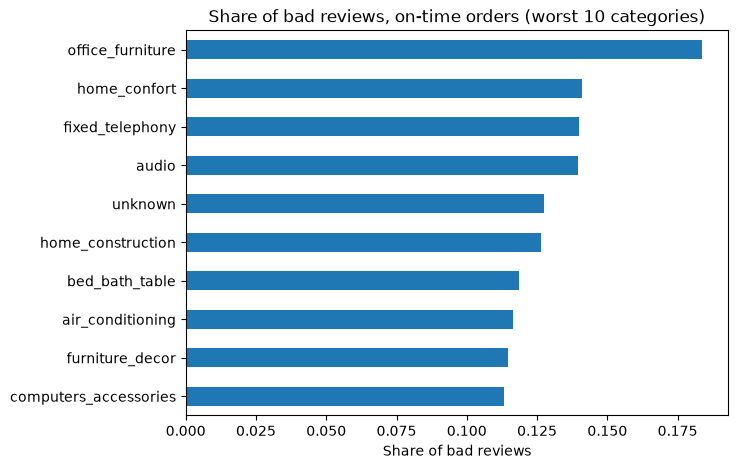

In [25]:
q8.head(10)['bad_share'].sort_values().plot(kind='barh', figsize=(7, 5))
plt.title('Share of bad reviews, on-time orders (worst 10 categories)')
plt.xlabel('Share of bad reviews')
plt.ylabel('')
plt.show()

In [26]:
q8['bad_reviews'] = (q8['orders'] * q8['bad_share']).round()
q8.sort_values('bad_reviews', ascending=False).head(5)

,orders,bad_share,avg_score,bad_reviews
category,,,,
bed_bath_table,8404,0.118396,4.152665,995.0
computers_accessories,6062,0.113164,4.205708,686.0
furniture_decor,5730,0.114660,4.205585,657.0
health_beauty,7929,0.073275,4.385925,581.0
sports_leisure,6960,0.075000,4.377155,522.0


**Finding:** Even with on-time delivery, some categories get far more bad reviews than the 9.2% average.
Office furniture is worst at 18.4% (1,137 orders), about double the average, followed by home comfort, fixed telephony and audio at about 14%.
The best categories are simple, standard products: food and drink (2.4%), books (3.5%) and luggage (5.5%).
Products with no category, description or photos ("unknown") get 12.8% bad reviews, above average, which suggests weak listings lead to disappointed customers.
By volume, large categories such as bed, bath & table (11.8% of 8,404 orders) produce the most bad reviews.

**For a shop:** for furniture and electronics, invest in better product information, photos, dimensions and packaging. Require complete listings, since empty listings perform worse. Stage 4 will read the comments to confirm the reasons.

## Q9. How do customers pay?
Payment types, use of installments, and whether installments link to order value or reviews.

In [27]:
payments = pd.read_csv(r"..\data\raw\olist_order_payments_dataset.csv")

main_type = (payments
    .sort_values('payment_value')
    .drop_duplicates(subset='order_id', keep='last')[['order_id', 'payment_type']])

main_type['payment_type'].value_counts(normalize=True).round(3) * 100

payment_type
credit_card    75.4
boleto         19.9
voucher         3.2
debit_card      1.5
not_defined     0.0
Name: proportion, dtype: float64

In [28]:
delivered['installment_group'] = pd.cut(
    delivered['max_installments'],
    bins=[-1, 1, 3, 6, 24],
    labels=['1 (paid at once)', '2-3', '4-6', '7-24']
)
delivered['installment_group'].value_counts(normalize=True).sort_index().round(3) * 100

installment_group
1 (paid at once)    48.5
2-3                 23.0
4-6                 16.3
7-24                12.2
Name: proportion, dtype: float64

In [29]:
q9 = delivered.groupby('installment_group', observed=True).agg(
    orders=('order_id', 'count'),
    median_paid=('total_paid', 'median'),
    bad_share=('is_bad', 'mean'),
)
q9.round(2)

,orders,median_paid,bad_share
installment_group,,,
1 (paid at once),46814,79.24,0.12
2-3,22161,111.82,0.13
4-6,15737,128.20,0.13
7-24,11763,206.54,0.15


**Finding:** Most orders are paid by credit card (75.4%), but one in five uses boleto (19.9%), a bank slip that needs no card; vouchers (3.2%) and debit (1.5%) are rare.
About half of orders (51.5%) are spread over several installments, and 12.2% over 7 to 24 months.
Larger orders use more installments: the median order paid at once is 79 BRL, against 207 BRL for 7 to 24 installments.
Bad reviews rise only slightly with installments (12% to 15%), likely because expensive orders include furniture and electronics, which get more bad reviews (Q8).

**For a shop:** offer boleto and installments, especially on higher-priced products; they make larger purchases possible. Payment method is not a major driver of reviews.

## Q10. Do customers come back?
Repeat purchase rate, and whether a bad first order makes customers less likely to return.

In [30]:
orders_sorted = orders.sort_values('order_purchase_timestamp')
orders_sorted['order_number'] = orders_sorted.groupby('customer_unique_id').cumcount() + 1
orders_sorted['order_number'].value_counts().sort_index().head()

order_number
1    96096
2     2997
3      252
4       49
5       19
Name: count, dtype: int64

In [31]:
n_orders = orders_sorted.groupby('customer_unique_id')['order_id'].count()
first = orders_sorted[orders_sorted['order_number'] == 1].copy()
first['came_back'] = first['customer_unique_id'].map(n_orders) > 1

In [32]:
first['first_bad'] = first['review_score'] <= 2
first.groupby('first_bad').agg(
    customers=('customer_unique_id', 'count'),
    came_back=('came_back', 'mean'),
).round(3)

,customers,came_back
first_bad,,
False,82067,0.031
True,14029,0.031


**Finding:** Only 3.1% of customers ever placed a second order (2,997 of 96,096); 252 placed a third and 19 a fifth.
The repeat rate is the same 3.1% whether the first order got a good or a bad review, so bad experiences are not what stops customers returning: almost nobody returns either way.
This points to a missing retention strategy rather than a service problem.

**For a shop:** the biggest growth opportunity is retention, not acquisition. Post-purchase emails, reorder reminders for repeat-purchase categories, and loyalty offers should be tested. Stage 2 segments customers to target this.

*Caveat: the data covers under two years, and many customers bought near the end, so the true repeat rate may be slightly higher.*

In [33]:
FIG = r"..\reports\figures"

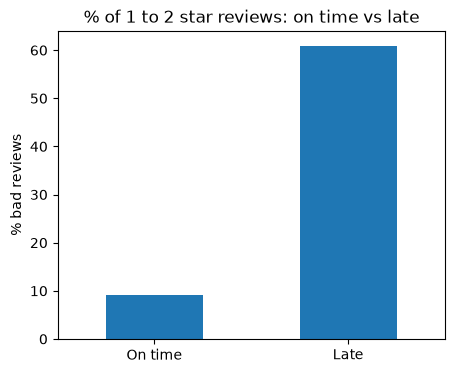

In [34]:
q4['bad_share'].plot(kind='bar', figsize=(5, 4))
plt.title('% of 1 to 2 star reviews: on time vs late')
plt.xticks([0, 1], ['On time', 'Late'], rotation=0)
plt.ylabel('% bad reviews')
plt.xlabel('')
plt.savefig(FIG + r"\q4_late_vs_reviews.png", dpi=150, bbox_inches='tight')
plt.show()